# Load simulation

In [1]:
import yt
import helper_functions as hf
import numpy as np
import matplotlib.pyplot as plt
from astropy.table import Table
yt.set_log_level("error")
from se_functions import find_bursts

In [2]:
df='/lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine'

In [3]:
target_sink=5

In [4]:
# Snapshot number
output=100

In [5]:
ts = hf.SinkDataLoader(df, sinkid=target_sink)
time = Table.read(df+'/ADAPTAclump_maps/output_step_redshift.txt', format='ascii')
snap_t   = np.array([float(t) for t in time['time']])
snap_out = np.array([int(o) for o in time['output']])

t_form = ts.data["time"][0]
z_form = ts.data["z"][0]

i_first = np.searchsorted(snap_t, t_form)
print("first snapshot:", snap_out[i_first])

first snapshot: 9


# Pipeline for saving profiles of cold gas and total gas

In [ ]:
outputs = range(snap_out[i_first], 117)

r_inner = 1e-4
r_log = np.linspace(0.2, 10, 64)
r_bins = np.r_[r_inner, r_log]

kw = dict(weight_field=None,
          units={("index","radius"): "kpc"},
          accumulation=True,
          override_bins = {("index", "radius") : r_bins})

r_list, Mcold_list, Mall_list, redshifts, times = [], [], [], [], []

In [ ]:
for out in outputs:
    ds = yt.load(hf.info_file(out, df))
    filename = f'{df}/output_{str(out).zfill(5)}/sink_{str(out).zfill(5)}.csv'
    t = Table.read(filename, format='ascii', names=['sink_id','BHmass','x','y','z','vx','vy','vz','tsink','dMdt'])
    c = ds.arr(t[t['sink_id']==target_sink]['x','y','z'][0].as_void().tolist(), 'code_length')

    sp = ds.sphere(c, (10, 'kpc'))
    cr = sp.cut_region(["obj['gas', 'temperature'] < 10**4.2"])

    p_all = yt.create_profile(sp, [("index", "radius")], [("gas", "mass")], **kw)
    p_cold = yt.create_profile(cr, [("index", "radius")], [("gas", "mass")], **kw)

    M_tot  = sp["gas", "mass"].sum().to("Msun").value
    M_last = p_all["gas", "mass"][-1].to("Msun").value
    if not np.isclose(M_tot, M_last, rtol=1e-6):
        print(f"output {out}: Missing mass {M_tot - M_last:.3e} Msun")

    r_list.append(p_all.x.to('kpc').value)
    Mcold_list.append(p_cold[("gas","mass")].to('Msun').value)
    Mall_list.append(p_all[("gas","mass")].to('Msun').value)
    redshifts.append(ds.current_redshift)
    times.append(ds.current_time)

    p_all.save_as_dataset(f"profiles/sink{target_sink}/Mall_sink{target_sink}_{out:05d}")
    p_cold.save_as_dataset(f"profiles/sink{target_sink}/Mcold_sink{target_sink}_{out:05d}")

In [ ]:
print(len(list(outputs)), len(redshifts), len(times), len(Mcold_list), len(Mall_list))

print(ts.data["time"][0])
print(np.min(ts.data["f_edd"][:100])) 

for out in outputs[::5]:
    ds = yt.load(hf.info_file(out, df))
    sp = ds.sphere(c, (2, "kpc"))
    print(out, sp["index", "dx"].to("pc").min())

In [ ]:
tab = Table(dict(
    output = list(outputs),
    z = redshifts,
    time = times,
    Mcold = np.array(Mcold_list),
    Mall = np.array(Mall_list)
))
tab["fraction"] = np.where(tab["Mall"] > 0, tab["Mcold"] / tab["Mall"], np.nan)

tab["Mcold"].unit = "Msun"
tab["Mall"].unit  = "Msun"
tab.meta.update(r_kpc=r_bins.tolist(), sink=int(target_sink), T_cut=10**4.2,
                note="cumulative M(<r); r_kpc = outer bin edge of each column element")

tab.write(f'profiles/sink{target_sink}/table_{target_sink}_{output}.ecsv', overwrite=True)

# Load saved table for profiles

In [6]:
tab = Table.read(f"profiles/sink{target_sink}/table_{target_sink}_{output}.ecsv")

In [7]:
mask_snap = (snap_out >= snap_out[i_first])

print(ts.data.colnames)

['nstep', 'aexp', 'time', 'BHmass', 'position', 'vsink', 'dotMbondi', 'dotMedd', 'rg_scale', 'spinmag', 'dMgrowth', 'dMaccr', 'Esave', 'bhspin', 'jsink', 'Efeed', 'f_edd', 'eps_sink', 'eta_disk', 'eta_jet', 'Mass_loading_factor', 'Rb', 'Ra', 'Rbhl', 'Rbhl_cell', 'Ra_cell', 'Rb_cell', 'dtnew', 'dotMgrowth', 'dotMaccr', 'Efeed_Th', 'Efeed_Ki', 'alpha_madau', 'beta_eff', 'z']


In [8]:
index = np.argmin(np.abs(np.array(tab.meta["r_kpc"]) - 1))
print(index)
print(tab.meta["r_kpc"][index])
print(tab['time'])

6
0.9777777777777779
        time       
-------------------
0.22403137805411494
 0.2271442555875377
0.23692624982626473
0.24746354325719983
 0.2483663171159391
0.25876277440161327
0.26869433286099736
 0.2709758605568155
0.28417057298409126
 0.2860760937494982
                ...
  0.957073815898591
 0.9710447510622852
 0.9846973134415559
   0.99829940518505
  1.011625143621938
 1.0244981341538841
  1.037611913962108
  1.051071665061889
  1.064895722436976
 1.0791422912163637
Length = 108 rows


# Plotting

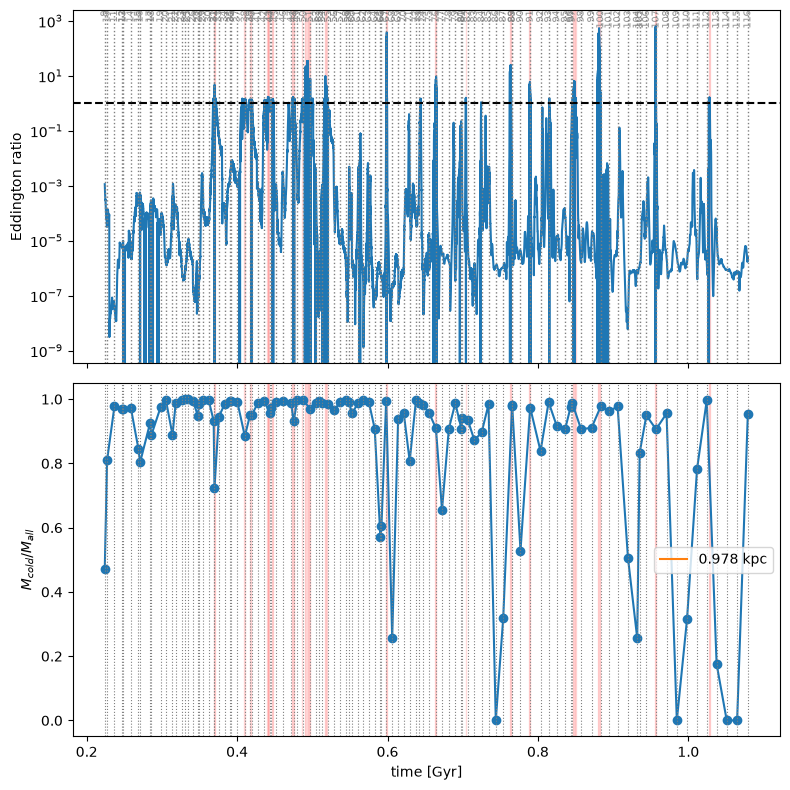

In [9]:
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(8, 8))
tab_times = tab['time']
tmin = tab_times[0]
tmax = tab_times[-1]

ts_times = ts.data['time']
mask = (ts_times >= tmin) & (ts_times <= tmax)
ratio = ts.data['dotMaccr']/ts.data['dotMedd']
ax1.plot(ts_times[mask], ratio[mask])
ax1.set_yscale('log')
ax1.set_ylabel('Eddington ratio')
ax1.axhline(1.0, ls='--', color='k')

ax2.plot(tab['time'], tab['fraction'][:, index], 'o-')
ax2.plot([], [], label=f'{tab.meta["r_kpc"][index]:.3g} kpc')
ax2.legend()
ax2.set_ylabel(r'$M_{cold} / M_{all}$')

ax2.set_xlabel('time [Gyr]')

output_labels = [str(o) for o in snap_out[mask_snap]]

ymin1, ymax1 = ax1.get_ylim()
label_y = ymax1 * 0.95

axes = (ax1, ax2)

catalogue = find_bursts(ts.data, gap_myr=0.2, min_dur_myr=0.1)
for t_start, t_end in zip(catalogue['t_start_myr'], catalogue['t_end_myr']):
    t_start, t_end = t_start * 1e-3, t_end * 1e-3
    if t_start > tmin and t_end < tmax:
        ax1.axvspan(t_start, t_end, color='r', alpha=0.15)
        ax2.axvspan(t_start, t_end, color='r', alpha=0.15)

for tt, label in zip(tab_times, output_labels): 
    axes[0].axvline(tt, color='grey', ls=':', lw=1)
    axes[1].axvline(tt, color='grey', ls=':', lw=0.8)
    axes[0].text(tt, label_y, label, color='grey', fontsize=7, rotation=90, va='top', ha='center', alpha=0.8)

plt.tight_layout()

# plt.savefig(f"fig/cold_fraction/{target_sink}_{output}_all")

In [10]:
catalogue

i_start,i_end,t_start_myr,t_end_myr,duration_myr,z_start,z_end,aexp_start,aexp_end,M_start,M_end,dM_accr,E_feed,E_feed_Th,E_feed_Ki,f_edd_max,dM_edd_max
int64,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64
12211,12411,369.1103266878421,370.46740178056774,1.3570750927256654,12.018469764172314,11.986647081193217,0.076813943429209,0.077002169516731,149333.661496089,165617.597375736,16380.347216652659,0.0,0.0,0.0,1.69360336423474,4.731122829532642
17062,17098,409.2024023263304,409.55305398408314,0.350651657752735,11.153292683369743,11.146351830099016,0.082282228039186,0.082329247002542,233979.953569637,236631.511042914,2792.849336492833,0.0,0.0,0.0,1.00830053534364,1.4125517923550879
17167,17218,410.25905206453336,410.73037867090744,0.47132660637407753,11.132407185578131,11.123119930578854,0.082423873902675,0.082487017015945,243234.860941262,247737.327785237,4655.8104230440795,0.0,0.0,0.0,1.01290865229912,1.4207020132507018
17887,17917,417.4417641845272,417.7484144222273,0.30665023770012567,10.992774540208154,10.986902352872718,0.083383540368186,0.083424388600308,292435.971973695,295128.28572574,2825.036631960725,0.0,0.0,0.0,1.01151493597942,1.3113615187292842
17984,18043,418.35985053732134,418.9151378771312,0.5552873398098654,10.975215088698258,10.964625708693612,0.083505807001643,0.083579714430464,301938.470908144,307470.749466234,5673.55900212309,0.0,0.0,0.0,1.02596238399855,1.3630911139548467
20663,20721,439.4711605699558,439.91997445665976,0.4488138867039311,10.588391528714613,10.580504583435344,0.086293252823062,0.086352023160579,358791.574552466,362207.192425733,3505.3166770936637,0.0,0.0,0.0,1.00817388191007,1.2768654661160284
20827,20882,440.73422861399183,441.1546493910088,0.42042077701694325,10.566229973844548,10.55887680515836,0.086458595606465,0.086513596161327,364877.0382971,368380.555186012,3587.956582194094,0.0,0.0,0.0,1.18935097379777,1.7171438575323026
20908,21033,441.35482805854616,442.33050827741613,0.975680218869968,10.555379777178798,10.538372852776222,0.086539777946108,0.086667332799823,370102.958011598,379022.468045619,8999.35292793196,0.0,0.0,0.0,1.17568931871791,1.6849274824012217
21559,21826,445.8375954145052,447.91798847686965,2.0803930623644646,10.477753909647626,10.442168955664618,0.087125060170479,0.08739601764969,411223.126284556,433725.033425852,22588.365857805868,0.0,0.0,0.0,1.0448337216386,1.4072942732189435


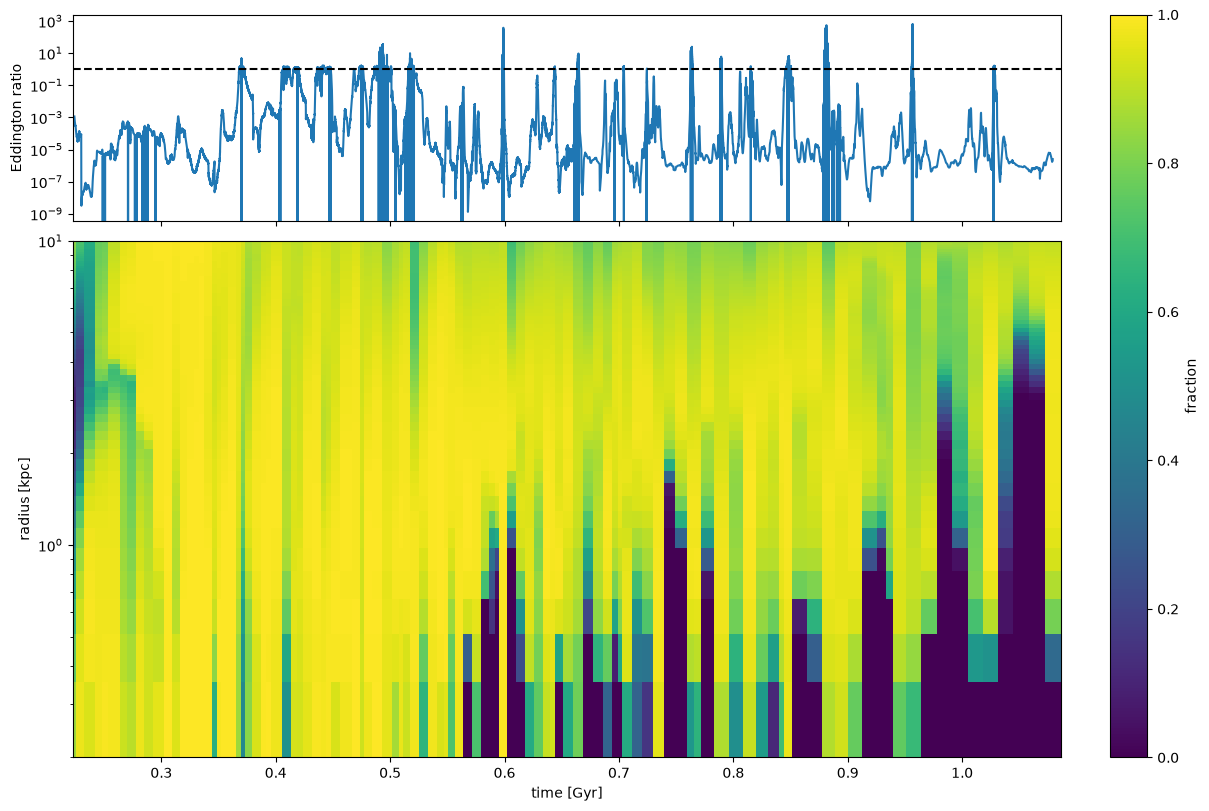

In [11]:
t = np.array(tab['time'])
t_mid = 0.5 * (t[1:] + t[:-1])
t_edge = np.r_[t[0] - (t_mid[0] - t[0]), t_mid, t[-1] + (t[-1] - t_mid[-1])]

fig, axes = plt.subplots(2, 1, figsize=(12, 8), height_ratios=[1, 2.5], sharex=True, layout="constrained")

ratio = ts.data['dotMaccr']/ts.data['dotMedd']

axes[0].plot(ts_times[mask], ratio[mask])
axes[0].set_yscale('log')
axes[0].set_ylabel('Eddington ratio')
axes[0].axhline(1.0, ls='--', color='k')

pcm = axes[1].pcolormesh(t_edge, tab.meta['r_kpc'], tab['fraction'].T)
fig.colorbar(pcm, ax=axes ,label='fraction')
axes[1].set_ylim(0.2, 10)
axes[1].set_ylabel('radius [kpc]')
axes[1].set_xlabel('time [Gyr]')
axes[1].set_yscale("log")


# plt.savefig(f'fig/cold_fraction/pcm_{target_sink}_all')

# Load galaxy catalogue from the last snapshot

In [12]:
import galaxy_catalogue.adaptahop_functions as ah
from astropy.io import ascii

In [13]:
# 2 for galaxy catalogue and 5 for merger tree
output=116
catalogue = ah.load_catalogue(output, df)

positions = np.column_stack([catalogue['x'], catalogue['y'], catalogue['z']])

# Load the target sink

In [14]:
filename = f'{df}/output_{str(output).zfill(5)}/sink_{str(output).zfill(5)}.csv'
t = Table.read(filename, format='ascii', names=['sink_id','BHmass','x','y','z','vx','vy','vz','tsink','dMdt'])
x_bh = np.array(t[t['sink_id'] == target_sink]['x', 'y', 'z'][0].as_void().tolist())
print(x_bh)

t[t['sink_id'] == target_sink]

[0.50392086 0.50052324 0.50458063]


sink_id,BHmass,x,y,z,vx,vy,vz,tsink,dMdt
int64,float64,float64,float64,float64,float64,float64,float64,float64,float64
5,2.3092291284e-11,0.50392086288,0.50052324275,0.50458062603,0.0003220249806,0.00075789153066,0.0013931329015,6.3638087639,6.6748584661e-16


# Closest Galaxy

In [15]:
d = np.linalg.norm(x_bh - positions, axis = 1)

sub_host = np.argmin(d)

x_sub_host = np.array(catalogue[sub_host]['x' , 'y', 'z'].as_void().tolist())

id_sub = catalogue[sub_host]["id"]

print(sub_host)
print(catalogue[sub_host])
print(x_sub_host)

106
 id level    mass            x                 y                 z             r50             density       
--- ----- ---------- ----------------- ----------------- ----------------- ------------ ---------------------
209     2 47935311.0 0.503923322356296 0.500536198728329 0.504582909879377 1.467754e-06 3.619154490890669e+24
[0.50392332 0.5005362  0.50458291]


# Filtering for only level 1

In [16]:
main_cat = catalogue[catalogue['level'] == 1]

pos_main = np.column_stack([main_cat['x'], main_cat['y'], main_cat['z']])
r50_main = np.array(main_cat['r50'])

d_main = np.linalg.norm(pos_main - x_bh, axis=1)
ratio  = d_main / r50_main

host = np.argmin(ratio)
host_id = main_cat['id'][host]
print(main_cat[host], f"d/r50 = {ratio[host]:.2f}")
print(t[t['sink_id'] == target_sink]['BHmass'][0])

ts=hf.SinkDataLoader(df,sinkid=target_sink)

print(ts.data['BHmass'][-1])

 id level      mass             x                 y                 z              r50             density       
--- ----- ------------- ----------------- ----------------- ----------------- ------------- ---------------------
  3     1 33561167000.0 0.503924512453878 0.500544282459122 0.504602857933187 6.6181096e-06 2.764054356101883e+25 d/r50 = 4.66
2.3092291284e-11
359189799.748292


In [17]:
ds = yt.load(hf.info_file(output, df))

c_gal = ds.arr(pos_main[host], "code_length")
c_bh  = ds.arr(x_bh, "code_length")
r50 = ds.quan(r50_main[host], "code_length")
x_sub_host = ds.arr(x_sub_host, "code_length")

print("Current redshift:", ds.current_redshift)
print("BH-gal distance:", np.linalg.norm((c_bh - c_gal).to("kpc")))
print("r50:  ", r50.to("kpc"))
# print(ds.index.get_smallest_dx().to("kpc"))

Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00116/info_00116.txt
Current redshift: 5.361677920172157
BH-gal distance: 3.561613621792605 kpc
r50:   0.7646499637056466 kpc


yt : [WARNING  ] 2026-11-23 12:21:30,648 The DM particle filter already exists. Overriding.
yt : [WARNING  ] 2026-11-23 12:21:30,649 The star particle filter already exists. Overriding.
yt : [WARNING  ] 2026-11-23 12:21:30,649 The cloud particle filter already exists. Overriding.
yt : [WARNING  ] 2026-11-23 12:21:30,650 The dust particle filter already exists. Overriding.
yt : [WARNING  ] 2026-11-23 12:21:30,650 The star_tracer particle filter already exists. Overriding.
yt : [WARNING  ] 2026-11-23 12:21:30,651 The cloud_tracer particle filter already exists. Overriding.
yt : [WARNING  ] 2026-11-23 12:21:30,651 The dust_tracer particle filter already exists. Overriding.
yt : [WARNING  ] 2026-11-23 12:21:30,652 The gas_tracer particle filter already exists. Overriding.



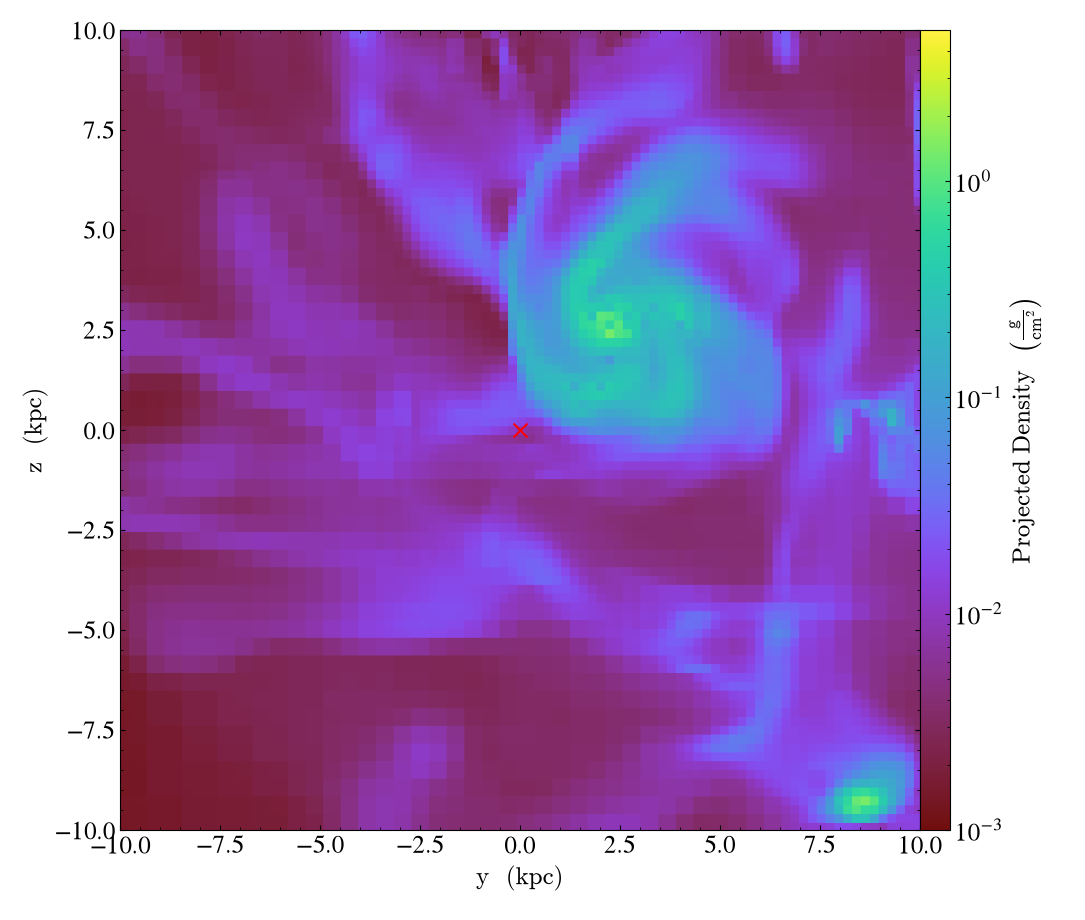

In [32]:
# Make plot centred on BH 17, zooming in to the central 10 kpc
width = ds.quan(20, 'kpc')  # Width of your plot
region = ds.sphere(c_bh, width)  # Make a sphere with the data you want to plot
p = yt.ProjectionPlot(ds, normal='x', fields=('gas', 'density'), width=width, data_source=region, center=c_bh)
p.annotate_marker(region.center, coord_system='data', color='red', s=100)
p.set_zlim(('gas','density'), 1e-3, 5)

# p.save(f'fig/most_massive/density_density_{output:03d}_{width.value}.png')
p.show()

('io', 'sink_csv', 'sink', 'nbody', 'DM', 'star', 'cloud', 'dust', 'star_tracer', 'cloud_tracer', 'dust_tracer', 'gas_tracer')



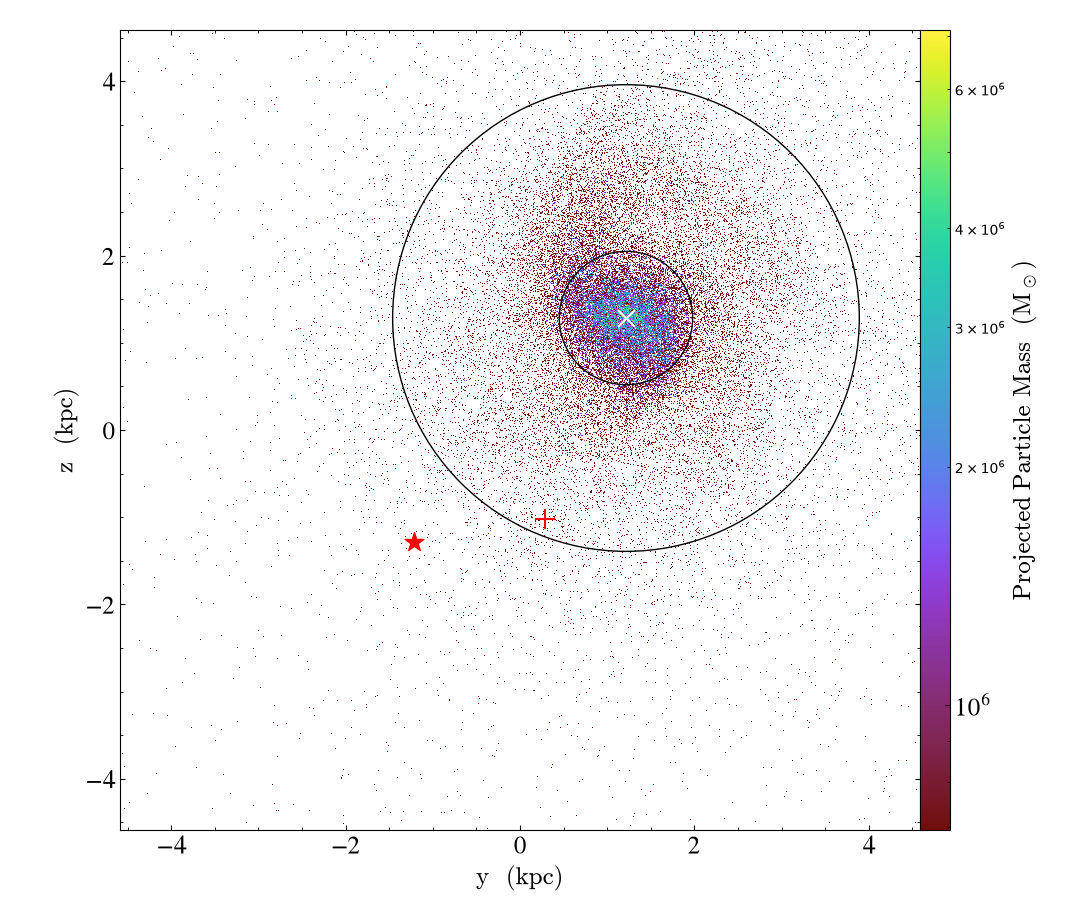

In [ ]:
center = 0.5 * (c_gal + c_bh)
W      = 12 * r50
box    = ds.box(center - W / 2, center + W / 2)

print(ds.particle_types)

p = yt.ParticleProjectionPlot(ds, "x", ("star", "particle_mass"),
                              center=center, width=W, data_source=box)
p.set_unit(("star", "particle_mass"), "Msun")

p.annotate_marker(c_gal, coord_system="data", marker="x", color="white", s=150)
p.annotate_marker(c_bh,  coord_system="data", marker="*", color="red",   s=200)
p.annotate_marker(x_sub_host, coord_system='data', marker='+', color='red', s=200)
p.annotate_sphere(c_gal, radius=r50,       circle_args={"color": "black"})
p.annotate_sphere(c_gal, radius=3.5 * r50, circle_args={"color": "black"})
p.show()

In [ ]:
[f for f in ds.derived_field_list if "star" in f[0]] 

This output contains 684 black holes



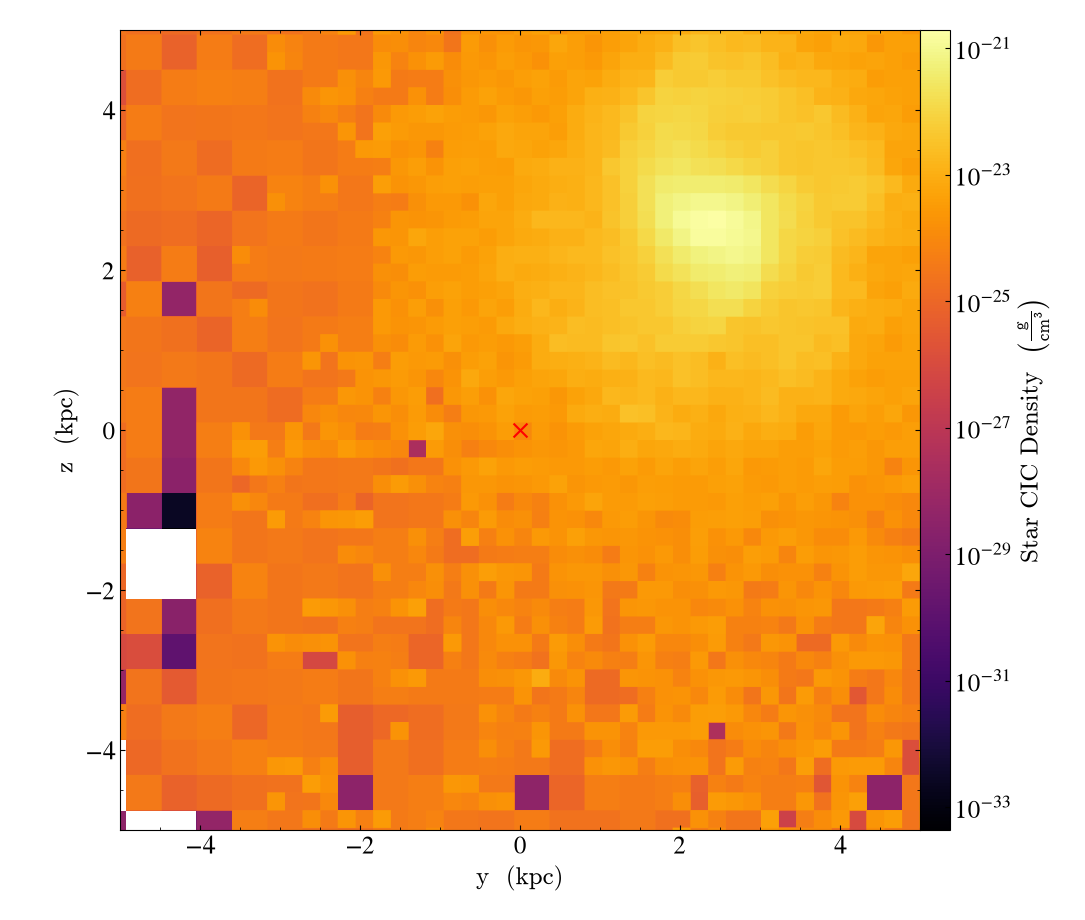

In [34]:
# Load position from file at this output
filename=f'{df}/output_{str(output).zfill(5)}/sink_{str(output).zfill(5)}.csv'
t = Table.read(filename,format='ascii',names=['sink_id','BHmass','x','y','z','vx','vy','vz','tsink','dMdt'])
print("This output contains",len(t),"black holes")

# Find position of target BH
sink_pos=t[t['sink_id']==target_sink]['x','y','z'] # Position on 6th sink
sink_pos_ds=ds.arr(sink_pos[0].as_void().tolist(),'code_length') #Position converted to something the dataset understands by adding units and stripping formatting

# Make plot centred on BH 17, zooming in to the central 300 kpc\
width=ds.quan(10,'kpc')  #Width of your plot
region=ds.sphere(sink_pos_ds,width) # Make a sphere with the data you want to plot

# Plot stellar distribution instead, reusing the data objects
field=('deposit','star_cic')
p = yt.ProjectionPlot(ds, normal='x', fields=[field],
                      width=width, data_source=region, 
                      center=sink_pos_ds,weight_field=field)
p.annotate_marker(region.center, coord_system='data', color='red', s=100)

# Use inferno colormap for the stellar field
p.set_cmap(field, 'inferno')

p.show()

In [18]:
outs, ratio_list, mass_list, BHmass_list, gal_centre = [], [], [], [], []
gal_centre={}

structure_folder='/ADAPTAclump_maps/'
df_tree=df+structure_folder+'/4_merger_trees/'
tree_file_name=df_tree+f'/data_tree_{str(host_id).zfill(6)}_MSM.dat'
data=ascii.read(tree_file_name,names=['level','snapshot','gal_id','empty1','empty2','child_id','parent_id','no_idea1','no_idea2','Mgal'])

main = data[data["level"] == 1]
main['snapshot'] = main['snapshot'] + 24

start = np.max([25, snap_out[i_first]])

for r in main:
    out = r['snapshot']
    cat = ah.load_catalogue(out, df)

    filename = f'{df}/output_{out:05d}/sink_{out:05d}.csv'
    t = Table.read(filename, format='ascii', names=['sink_id','BHmass','x','y','z','vx','vy','vz','tsink','dMdt'])
    row = t[t['sink_id'] == target_sink]
    xb = np.array(row['x','y','z'][0].as_void().tolist())

    gal = cat[cat["id"] == r["gal_id"]]

    pos  = np.column_stack([gal['x'], gal['y'], gal['z']])
    d    = np.linalg.norm(pos - xb, axis=1)
    k    = np.argmin(d / np.array(gal['r50']))

    outs.append(out)
    ratio_list.append(d[k] / gal['r50'][k])
    mass_list.append(gal['mass'][k])
    my_unit = ds.quan(1, "code_mass").to("Msun").value
    BHmass_list.append(t[t["sink_id"]==target_sink]['BHmass'][0] * my_unit)
    gal_centre[out] = gal['x', 'y', 'z'][0].as_void().tolist()

t_snap = np.array([snap_t[snap_out == o][0] for o in outs])

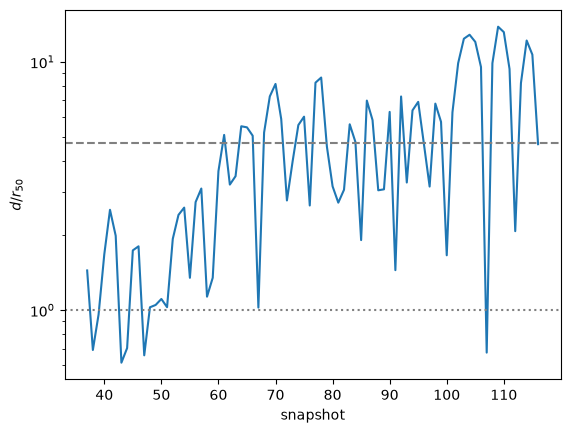

In [19]:
plt.plot(outs, ratio_list)
plt.axhline(1, ls=':', c='grey')
plt.axhline(np.mean(ratio_list), ls='--', c='grey')
plt.xlabel("snapshot")
plt.ylabel(r'$d/r_{50}$')
plt.yscale("log")

In [20]:
print(np.array(gal_centre).shape)

()


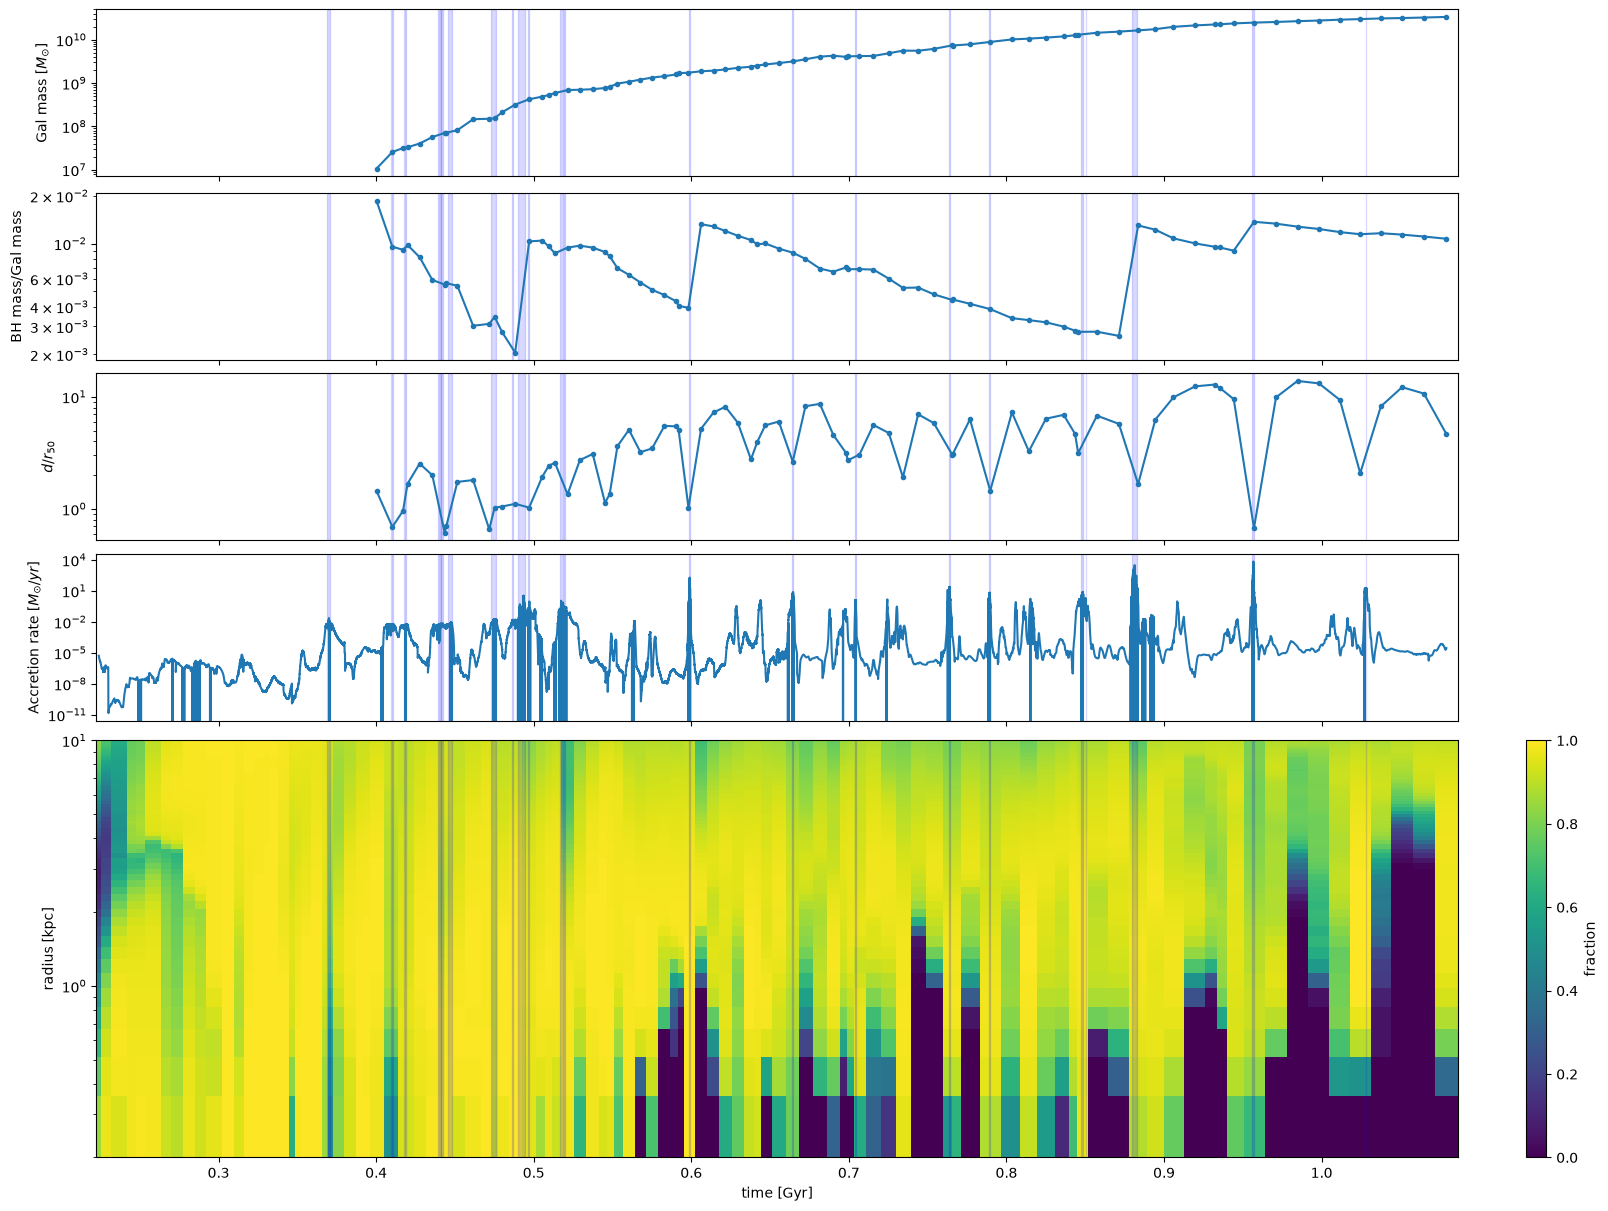

In [21]:
fig, axes = plt.subplots(5, 1, figsize=(16, 12), height_ratios=[1, 1, 1, 1, 2.5], sharex=True, layout="constrained")

axes[0].plot(t_snap, np.array(mass_list), '.-')
axes[0].set_yscale("log")
axes[0].set_ylabel(r"Gal mass $[M_{\odot}]$")

axes[1].plot(t_snap, np.array(BHmass_list) / np.array(mass_list), '.-')
axes[1].set_yscale("log")
axes[1].set_ylabel("BH mass/Gal mass")

axes[2].plot(t_snap, ratio_list, '.-')
axes[2].set_yscale("log")
axes[2].set_ylabel(r'$d/r_{50}$')
# axes[2].axhline(np.mean(ratio_list), ls='--', c='grey')

ratio = ts.data['dotMaccr']/ts.data['dotMedd']

axes[3].plot(ts_times[mask], ts.data["dotMaccr"][mask])
axes[3].set_yscale('log')
axes[3].set_ylabel(r'Accretion rate [$M_{\odot}/yr$]')

pcm = axes[4].pcolormesh(t_edge, tab.meta['r_kpc'], tab['fraction'].T)
fig.colorbar(pcm, ax=axes[4], label='fraction')
axes[4].set_ylim(0.2, 10)
axes[4].set_ylabel('radius [kpc]')
axes[4].set_xlabel('time [Gyr]')
axes[4].set_yscale("log")

catalogue = find_bursts(ts.data, gap_myr=0.2, min_dur_myr=0.1)
for t_start, t_end in zip(catalogue['t_start_myr'], catalogue['t_end_myr']):
    t_start, t_end = t_start * 1e-3, t_end * 1e-3
    for i in range(5):
        if i == 4:
            axes[i].axvspan(t_start, t_end, color='blue', alpha=0.15)
        else:
            axes[i].axvspan(t_start, t_end, color='blue', alpha=0.15)

# plt.savefig(f"fig/cold_fraction/many_{target_sink}")
        

Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00106/info_00106.txt


yt : [WARNING  ] 2026-11-26 18:36:44,181 The DM particle filter already exists. Overriding.
yt : [WARNING  ] 2026-11-26 18:36:44,182 The star particle filter already exists. Overriding.
yt : [WARNING  ] 2026-11-26 18:36:44,183 The cloud particle filter already exists. Overriding.
yt : [WARNING  ] 2026-11-26 18:36:44,184 The dust particle filter already exists. Overriding.
yt : [WARNING  ] 2026-11-26 18:36:44,184 The star_tracer particle filter already exists. Overriding.
yt : [WARNING  ] 2026-11-26 18:36:44,185 The cloud_tracer particle filter already exists. Overriding.
yt : [WARNING  ] 2026-11-26 18:36:44,185 The dust_tracer particle filter already exists. Overriding.
yt : [WARNING  ] 2026-11-26 18:36:44,186 The gas_tracer particle filter already exists. Overriding.


Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00107/info_00107.txt


yt : [WARNING  ] 2026-11-26 18:36:49,969 The DM particle filter already exists. Overriding.
yt : [WARNING  ] 2026-11-26 18:36:49,970 The star particle filter already exists. Overriding.
yt : [WARNING  ] 2026-11-26 18:36:49,971 The cloud particle filter already exists. Overriding.
yt : [WARNING  ] 2026-11-26 18:36:49,971 The dust particle filter already exists. Overriding.
yt : [WARNING  ] 2026-11-26 18:36:49,972 The star_tracer particle filter already exists. Overriding.
yt : [WARNING  ] 2026-11-26 18:36:49,972 The cloud_tracer particle filter already exists. Overriding.
yt : [WARNING  ] 2026-11-26 18:36:49,973 The dust_tracer particle filter already exists. Overriding.
yt : [WARNING  ] 2026-11-26 18:36:49,974 The gas_tracer particle filter already exists. Overriding.


Opening /lustre/dirac3/scratch/dp368/shared/Zsuperedd/Zsuperedd_refine/output_00108/info_00108.txt


yt : [WARNING  ] 2026-11-26 18:36:54,067 The DM particle filter already exists. Overriding.
yt : [WARNING  ] 2026-11-26 18:36:54,068 The star particle filter already exists. Overriding.
yt : [WARNING  ] 2026-11-26 18:36:54,068 The cloud particle filter already exists. Overriding.
yt : [WARNING  ] 2026-11-26 18:36:54,068 The dust particle filter already exists. Overriding.
yt : [WARNING  ] 2026-11-26 18:36:54,069 The star_tracer particle filter already exists. Overriding.
yt : [WARNING  ] 2026-11-26 18:36:54,069 The cloud_tracer particle filter already exists. Overriding.
yt : [WARNING  ] 2026-11-26 18:36:54,069 The dust_tracer particle filter already exists. Overriding.
yt : [WARNING  ] 2026-11-26 18:36:54,070 The gas_tracer particle filter already exists. Overriding.


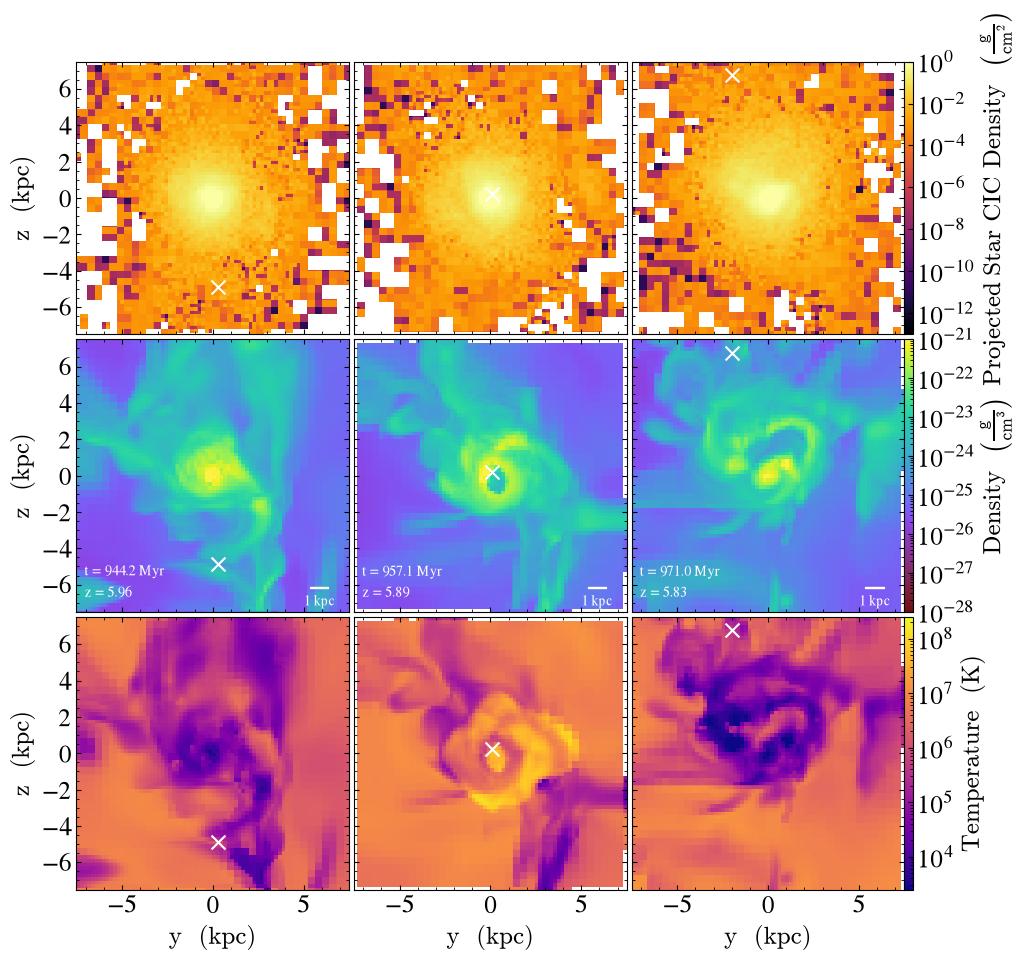

In [47]:
from mpl_toolkits.axes_grid1 import AxesGrid

W = 15

outs_sel = [106, 107, 108]   

fields = [("deposit", "star_cic"), ("gas", "density"), ("gas", "temperature")]
clims = {("deposit", "star_cic"): (1e-13, 1),
          ("gas", "density"): (1e-28, 1e-21),
          ("gas", "temperature"): (2.5e3, 2.5e8)}
cmaps = {("deposit", "star_cic"): "inferno",
          ("gas", "density"): None,
          ("gas", "temperature"): "plasma"}

fig  = plt.figure(figsize=(13, 12))

grid = AxesGrid(fig, 
                (0.05, 0.05, 0.9, 0.9), 
                nrows_ncols=(3, 3),
                axes_pad=0.05, 
                label_mode="L", 
                share_all=True,
                cbar_location="right", 
                cbar_mode="edge",
                cbar_size="3%", 
                cbar_pad="0%")

for j, out in enumerate(outs_sel):
    ds   = yt.load(hf.info_file(out, df))
    c    = ds.arr(gal_centre[out], "code_length")
    half = ds.arr([2.0, W / 2, W / 2], "kpc")
    box  = ds.box(c - half, c + half)

    filename = f'{df}/output_{out:05d}/sink_{out:05d}.csv'
    t = Table.read(filename, format='ascii', names=['sink_id','BHmass','x','y','z','vx','vy','vz','tsink','dMdt'])
    row = t[t['sink_id'] == target_sink]
    xb = np.array(row['x','y','z'][0].as_void().tolist())

    for i, f in enumerate(fields):
        w = ("gas", "density") if f[0] == "gas" else None
        p = yt.ProjectionPlot(ds, "x", f, center=c, width=(W, "kpc"),
                              data_source=box, weight_field=w)
        p.set_cmap(f, cmaps[f])
        p.annotate_marker(ds.arr(xb, "code_length"), coord_system='data', color='white', s=100)
        p.set_zlim(f, *clims[f])

        if i == 1:
            p.annotate_timestamp(redshift=True, text_args={"size": 10})
            p.annotate_scale(text_args={"size": 10})

        k = i * 3 + j
        plot = p.plots[f]
        plot.figure = fig
        plot.axes = grid[k].axes
        plot.cax = grid.cbar_axes[i]
        p.render()

# fig.savefig("fig/orbit_snapshots.png", dpi=200)

In [ ]:
out  = 116
cat  = ah.load_catalogue(out, df)
main = cat[cat['level'] == 1]
pos  = np.column_stack([main['x'], main['y'], main['z']])
mgal = np.array(main['mass'])

sinks = Table.read(f'{df}/output_{out:05d}/sink_{out:05d}.csv', format='ascii',
                   names=['sink_id','BHmass','x','y','z','vx','vy','vz','tsink','dMdt'])

rows = []
for s in sinks:
    xb = np.array([s['x'], s['y'], s['z']])
    d  = np.linalg.norm(pos - xb, axis=1)
    k  = np.argmax(mgal / d**2)
    rows.append((s['sink_id'], s['BHmass'] * my_unit, mgal[k], d[k] / main['r50'][k]))

pop = Table(rows=rows, names=['sink_id', 'Mbh', 'Mgal', 'd_r50'])